# Stochastic simulation from scratch: random variates, input modelling and discrete-event models

This notebook walks through the main building blocks of a simulation study, one at a time:

1. **Random-variate generation:** inverse-transform generators for continuous, piecewise and discrete distributions, checked against the theoretical CDF.
2. **Input modelling:** a Q-Q plot for the exponential distribution and a chi-square goodness-of-fit test for the normal distribution.
3. **Dump-truck system, two ways:**
   - a hand-written *event-scheduling* simulation with a future event list;
   - the same system as a *process-interaction* model in SimPy.

   The two implementations are checked against each other.
4. **Job shop:** a four-station, four-job-type SimPy model with a warm-up period, 20 independent replications and 95% confidence intervals.

All randomness is seeded, so every number below can be reproduced.

In [1]:
%matplotlib inline
from heapq import heappush, heappop

import numpy as np
import scipy.stats as stats
import simpy as sp
import matplotlib.pyplot as plt

plt.rcParams["figure.figsize"] = (6, 3.5)

## 1. Random-variate generation (inverse transform)

If $R \sim U(0,1)$ and $F$ is a CDF, then $X = F^{-1}(R)$ has CDF $F$. Each generator below inverts $F$ by hand. Every generator draws 10,000 values; the histogram is compared with the true density, and a Kolmogorov–Smirnov (or chi-square, for the discrete case) test checks the fit.

**1a. Two-sided exponential (Laplace with rate 2):** $f(x) = e^{2x}$ for $x \le 0$ and $e^{-2x}$ for $x > 0$.

Then $F(x) = \tfrac12 e^{2x}$ for $x \le 0$ and $1 - \tfrac12 e^{-2x}$ for $x > 0$, so
$X = \tfrac12 \ln(2R)$ if $R \le \tfrac12$ and $X = -\tfrac12 \ln(2 - 2R)$ otherwise.

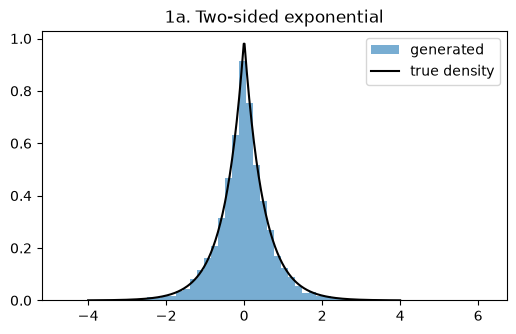

mean -0.004 (true 0), variance 0.511 (true 0.5), KS p-value 0.603


In [2]:
def laplace_inverse_transform(N, rng):
    R = rng.random(N)
    return np.where(R <= 0.5, np.log(2 * R) / 2, -np.log(2 - 2 * R) / 2)

rng = np.random.default_rng(2022)
X1 = laplace_inverse_transform(10_000, rng)

grid = np.linspace(-4, 4, 400)
plt.hist(X1, bins=60, density=True, alpha=0.6, label="generated")
plt.plot(grid, np.exp(-2 * np.abs(grid)), "k-", label="true density")
plt.legend(); plt.title("1a. Two-sided exponential"); plt.show()

ks = stats.kstest(X1, stats.laplace(scale=0.5).cdf)
print(f"mean {X1.mean():.3f} (true 0), variance {X1.var():.3f} (true 0.5), KS p-value {ks.pvalue:.3f}")

**1b. Piecewise CDF:** $F(x) = \tfrac12 + \tfrac{x}{6}$ on $(-3, 0]$ and $\tfrac12 + \tfrac{x^2}{32}$ on $(0, 4]$.

Inverting each piece gives $X = 6R - 3$ if $R \le \tfrac12$ and $X = \sqrt{32(R - \tfrac12)}$ otherwise.

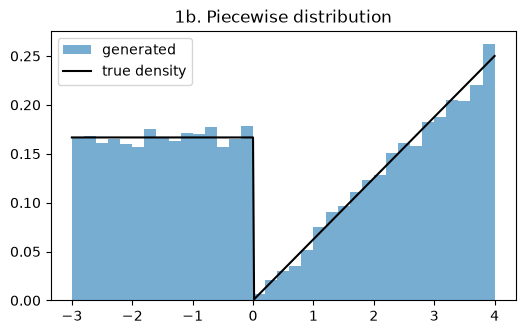

KS p-value 0.908


In [3]:
def piecewise_inverse_transform(N, rng):
    R = rng.random(N)
    return np.where(R <= 0.5, 6 * R - 3, np.sqrt(32 * np.clip(R - 0.5, 0, None)))

def piecewise_cdf(x):
    x = np.asarray(x, dtype=float)
    return np.select([x <= -3, x <= 0, x <= 4], [0, 0.5 + x / 6, 0.5 + x**2 / 32], 1.0)

X2 = piecewise_inverse_transform(10_000, rng)

grid = np.linspace(-3, 4, 400)
density = np.where(grid <= 0, 1 / 6, grid / 16)
plt.hist(X2, bins=35, density=True, alpha=0.6, label="generated")
plt.plot(grid, density, "k-", label="true density")
plt.legend(); plt.title("1b. Piecewise distribution"); plt.show()

print(f"KS p-value {stats.kstest(X2, piecewise_cdf).pvalue:.3f}")

**1c. Discrete distribution:** $F(x) = \dfrac{x(x+1)(2x+1)}{n(n+1)(2n+1)}$ for $x = 1, \dots, n$, with $n = 10$, so $P(X = x) \propto x^2$.

Discrete inverse transform: $X$ is the smallest $x$ with $F(x) \ge R$. Instead of writing out ten `if` branches, the CDF is computed once and searched with `np.searchsorted`.

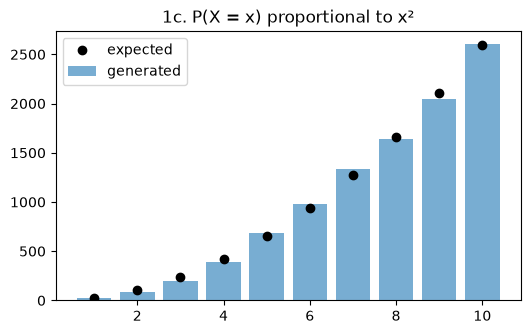

chi-square 18.35, p-value 0.031
share of 200 repeated tests rejected at 5%: 5.5%


In [4]:
def discrete_inverse_transform(N, rng, n=10):
    x = np.arange(1, n + 1)
    cdf = x * (x + 1) * (2 * x + 1) / (n * (n + 1) * (2 * n + 1))
    return x[np.searchsorted(cdf, rng.random(N))]

X3 = discrete_inverse_transform(10_000, rng)

x = np.arange(1, 11)
expected = 10_000 * x**2 / np.sum(x**2)
observed = np.bincount(X3, minlength=11)[1:]
plt.bar(x, observed, alpha=0.6, label="generated")
plt.plot(x, expected, "ko", label="expected")
plt.legend(); plt.title("1c. P(X = x) proportional to x²"); plt.show()

chi2 = stats.chisquare(observed, expected)
print(f"chi-square {chi2.statistic:.2f}, p-value {chi2.pvalue:.3f}")

# one test can reject a correct generator by chance (5% of the time at alpha = 0.05);
# repeating it on 200 independent samples shows whether rejections happen more often than that
pvals = [stats.chisquare(np.bincount(discrete_inverse_transform(10_000, rng), minlength=11)[1:], expected).pvalue
         for _ in range(200)]
print(f"share of 200 repeated tests rejected at 5%: {np.mean(np.array(pvals) < 0.05):.1%}")

A single p-value below 0.05 does not prove the generator wrong: with a correct generator, one test in twenty rejects by chance. Over 200 repetitions the rejection rate is close to the nominal 5%, which is what a correct generator should give.

**1d. Pallets per truck:** uniform between 8 and 24. A continuous $U(8, 24)$ is $X = 8 + 16R$. Pallet counts are integers, though, so the discrete uniform on $\{8, \dots, 24\}$ is $X = 8 + \lfloor 17R \rfloor$. Simply truncating $8 + 16R$ would never produce 24.

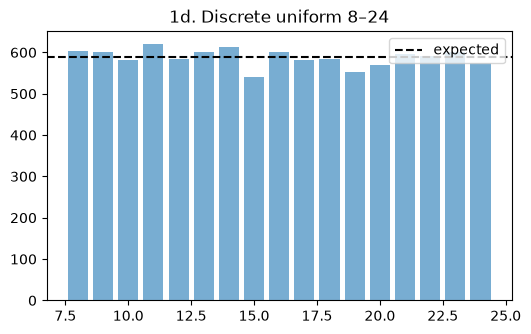

range: 8 - 24 | chi-square p-value: 0.766


In [5]:
def pallets(N, rng, a=8, b=24):
    return a + np.floor((b - a + 1) * rng.random(N)).astype(int)

X4 = pallets(10_000, rng)
counts = np.bincount(X4, minlength=25)[8:]
plt.bar(np.arange(8, 25), counts, alpha=0.6)
plt.axhline(10_000 / 17, color="k", ls="--", label="expected")
plt.legend(); plt.title("1d. Discrete uniform 8–24"); plt.show()
print("range:", X4.min(), "-", X4.max(), "| chi-square p-value:", round(stats.chisquare(counts).pvalue, 3))

## 2. Input modelling

Before a distribution is used as a simulation input, it has to fit the data. Two standard tools are implemented here and checked on samples where the right answer is known.

**2a. Q-Q plot for the exponential distribution.** The sorted data $x_{(j)}$ are plotted against the fitted quantiles $F^{-1}\big(\tfrac{j}{N+1}\big)$, with the rate estimated as $1/\bar{x}$. A good fit lies on the 45° line.

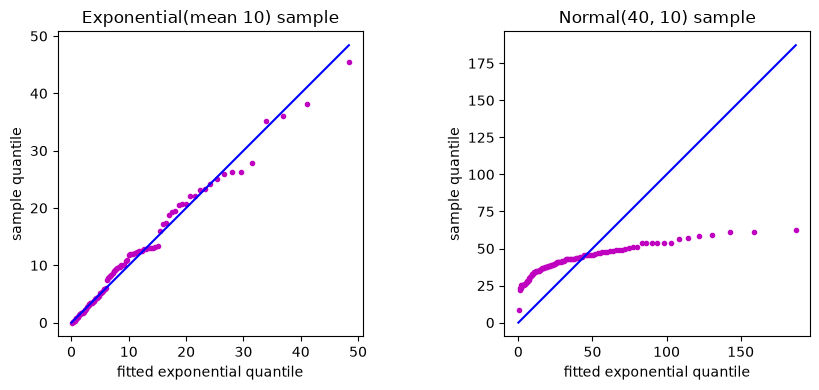

In [6]:
def exponential_qq_plot(X, ax, title):
    N = len(X)
    j = np.arange(1, N + 1)
    theoretical = stats.expon.ppf(j / (N + 1), scale=np.mean(X))
    ax.plot(theoretical, np.sort(X), "m.")
    lim = max(theoretical.max(), X.max())
    ax.plot([0, lim], [0, lim], "b-")
    ax.set_xlabel("fitted exponential quantile"); ax.set_ylabel("sample quantile")
    ax.set_title(title); ax.set_aspect("equal")

rng = np.random.default_rng(2022)
fig, axes = plt.subplots(1, 2, figsize=(9, 4))
exponential_qq_plot(rng.exponential(scale=10, size=100), axes[0], "Exponential(mean 10) sample")
exponential_qq_plot(rng.normal(loc=40, scale=10, size=100), axes[1], "Normal(40, 10) sample")
plt.tight_layout(); plt.show()

The exponential sample lies on the line. The normal sample bends into an S-shape: it has too few small values and too short a right tail for an exponential.

**2b. Chi-square test for normality, with equal-probability intervals.**
- The interval borders are the $\tfrac{i}{k}$ quantiles of the fitted normal, so every interval expects $N/k$ observations.
- The mean and standard deviation are estimated from the data, so the degrees of freedom are $k - 1 - 2$.

In [7]:
def normality_chi_square_test(X, k=10, alpha=0.05):
    mu, sigma = np.mean(X), np.std(X, ddof=1)
    borders = stats.norm.ppf(np.arange(k + 1) / k, loc=mu, scale=sigma)  # -inf ... +inf
    observed = np.histogram(X, bins=borders)[0]
    expected = np.full(k, len(X) / k)
    chi_square = np.sum((observed - expected) ** 2 / expected)
    critical = stats.chi2.ppf(1 - alpha, df=k - 1 - 2)
    return chi_square, critical

rng = np.random.default_rng(2022)
for N in (100, 1000):
    samples = {"Normal(240, 10)": rng.normal(240, 10, N), "Uniform(210, 270)": rng.uniform(210, 270, N)}
    for name, X in samples.items():
        chi_square, critical = normality_chi_square_test(X)
        verdict = "fail to reject normality" if chi_square <= critical else "reject normality"
        print(f"N = {N:4d}  {name:18s} chi-square = {chi_square:6.2f}  critical = {critical:.2f}  -> {verdict}")

# power: how often is the (non-normal) uniform sample rejected?
for N in (100, 1000):
    power = np.mean([np.subtract(*normality_chi_square_test(rng.uniform(210, 270, N))) > 0 for _ in range(500)])
    print(f"N = {N:4d}: uniform sample rejected in {power:.0%} of 500 repetitions")

N =  100  Normal(240, 10)    chi-square =   5.40  critical = 14.07  -> fail to reject normality
N =  100  Uniform(210, 270)  chi-square =   8.40  critical = 14.07  -> fail to reject normality
N = 1000  Normal(240, 10)    chi-square =   1.10  critical = 14.07  -> fail to reject normality
N = 1000  Uniform(210, 270)  chi-square =  85.12  critical = 14.07  -> reject normality


N =  100: uniform sample rejected in 35% of 500 repetitions
N = 1000: uniform sample rejected in 100% of 500 repetitions


The normal sample passes at both sizes. The uniform sample is the interesting case:
- With 100 observations it is **not** rejected here. Repeated over 500 samples, the test catches it only 35% of the time.
- With 1,000 observations it is rejected every time.

Goodness-of-fit tests have little power on small samples, so "fail to reject" is not proof of a good fit. A Q-Q plot should be read alongside the test.

## 3. Dump-truck system: event scheduling vs process interaction

**System.**
- Six trucks haul coal. Each truck is loaded at one of **two loaders**, then weighed on **one scale**, then travels (and unloads) before returning to the loader queue.
- Both queues are first-come-first-served.
- Loading, weighing and travel times are discrete distributions:

| Activity | Times (min) | Probabilities |
|---|---|---|
| Loading | 5 / 10 / 15 | 0.3 / 0.5 / 0.2 |
| Weighing | 12 / 16 | 0.7 / 0.3 |
| Travel | 40 / 60 / 80 / 100 | 0.4 / 0.3 / 0.2 / 0.1 |

**Goal:** loader and scale utilisation over an 8-hour (480-minute) shift.

The same system is built in the two classic simulation "world views":
- **Event scheduling (3.1):** the model keeps the system state and a future event list (FEL) by hand, and jumps from event to event.
- **Process interaction (3.2):** SimPy follows each truck through its life cycle, and the bookkeeping is handled by the library.

If both are correct, their long-run utilisations must agree (3.3).

In [8]:
def discrete_sampler(values, probs):
    cum = np.cumsum(probs)
    values = np.asarray(values)
    return lambda rng: int(values[np.searchsorted(cum, rng.random(), side="right")])

loading_time  = discrete_sampler([5, 10, 15], [0.3, 0.5, 0.2])
weighing_time = discrete_sampler([12, 16], [0.7, 0.3])
travel_time   = discrete_sampler([40, 60, 80, 100], [0.4, 0.3, 0.2, 0.1])

### 3.1 Event-scheduling model

- **State:** $LQ(t)$ trucks in the loader queue, $L(t) \in \{0,1,2\}$ trucks being loaded, $WQ(t)$ trucks in the weigh queue, $W(t) \in \{0,1\}$ trucks on the scale.
- **Events:**
  - ALQ: a truck arrives at the loader queue;
  - EL: end of loading;
  - EW: end of weighing;
  - ES: end of the simulation.
- **Cumulative statistics:** BL = total loader busy time, BS = total scale busy time. Between two events, BL grows by $L \cdot \Delta t$ and BS by $W \cdot \Delta t$.
- **Initial state:** DT1 is on the scale, DT2 and DT3 are being loaded, and DT4–DT6 wait in the loader queue.

In [9]:
def dump_truck_event_scheduling(T=480, seed=2022, trace=False):
    rng = np.random.default_rng(seed)
    clock, BL, BS = 0, 0, 0
    loader_queue, weigh_queue = ["DT4", "DT5", "DT6"], []
    L, W = 2, 1
    FEL = []
    heappush(FEL, (weighing_time(rng), "EW", "DT1"))
    heappush(FEL, (loading_time(rng), "EL", "DT2"))
    heappush(FEL, (loading_time(rng), "EL", "DT3"))
    heappush(FEL, (T, "ES", ""))

    rows = []
    def record():
        fel = " ".join(f"({e},{t},{d})" if d else f"({e},{t})" for t, e, d in sorted(FEL))
        rows.append(f"{clock:>5} | {len(loader_queue):>2} {L:>2} {len(weigh_queue):>2} {W:>2} | "
                    f"{BL:>4} {BS:>4} | {fel}")
    record()

    def start_weighing(truck):
        nonlocal W
        W = 1
        heappush(FEL, (clock + weighing_time(rng), "EW", truck))

    def start_loading(truck):
        nonlocal L
        L += 1
        heappush(FEL, (clock + loading_time(rng), "EL", truck))

    while True:
        event_time, event, truck = heappop(FEL)
        BL += L * (event_time - clock)          # update time-integrated busy counts
        BS += W * (event_time - clock)
        clock = event_time

        if event == "ES":
            break
        if event == "EL":                       # truck goes to the scale, loader takes the next truck
            L -= 1
            if W == 0:
                start_weighing(truck)
            else:
                weigh_queue.append(truck)
            if loader_queue:
                start_loading(loader_queue.pop(0))
        elif event == "EW":                     # truck leaves to unload, scale takes the next truck
            W = 0
            heappush(FEL, (clock + travel_time(rng), "ALQ", truck))
            if weigh_queue:
                start_weighing(weigh_queue.pop(0))
        elif event == "ALQ":                    # truck is back at the loaders
            if L < 2:
                start_loading(truck)
            else:
                loader_queue.append(truck)
        record()

    if trace:
        print("CLOCK | LQ  L WQ  W |   BL   BS | future event list")
        print("\n".join(rows[:12]))
        print(f"... ({len(rows) - 12} more events) ...")
    return BL / (2 * T), BS / T

loader_util, scale_util = dump_truck_event_scheduling(trace=True)
print(f"\nOne 480-minute shift: loader utilisation {loader_util:.3f}, scale utilisation {scale_util:.3f}")

CLOCK | LQ  L WQ  W |   BL   BS | future event list
    0 |  3  2  0  1 |    0    0 | (EL,5,DT2) (EL,10,DT3) (EW,12,DT1) (ES,480)
    5 |  2  2  1  1 |   10    5 | (EL,10,DT3) (EL,10,DT4) (EW,12,DT1) (ES,480)
   10 |  1  2  2  1 |   20   10 | (EL,10,DT4) (EW,12,DT1) (EL,20,DT5) (ES,480)
   10 |  0  2  3  1 |   20   10 | (EW,12,DT1) (EL,20,DT5) (EL,20,DT6) (ES,480)
   12 |  0  2  2  1 |   24   12 | (EL,20,DT5) (EL,20,DT6) (EW,24,DT2) (ALQ,52,DT1) (ES,480)
   20 |  0  1  3  1 |   40   20 | (EL,20,DT6) (EW,24,DT2) (ALQ,52,DT1) (ES,480)
   20 |  0  0  4  1 |   40   20 | (EW,24,DT2) (ALQ,52,DT1) (ES,480)
   24 |  0  0  3  1 |   40   24 | (EW,40,DT3) (ALQ,52,DT1) (ALQ,84,DT2) (ES,480)
   40 |  0  0  2  1 |   40   40 | (ALQ,52,DT1) (EW,52,DT4) (ALQ,84,DT2) (ALQ,140,DT3) (ES,480)
   52 |  0  1  2  1 |   40   52 | (EW,52,DT4) (EL,62,DT1) (ALQ,84,DT2) (ALQ,140,DT3) (ES,480)
   52 |  0  1  1  1 |   40   52 | (EL,62,DT1) (EW,64,DT5) (ALQ,84,DT2) (ALQ,92,DT4) (ALQ,140,DT3) (ES,480)
   62 |  0  0  2

### 3.2 Process-interaction model (SimPy)

Each truck is a SimPy process that loops through *load → weigh → travel*. The loaders and the scale are `Resource`s with capacity 2 and 1. A small `TrackedResource` subclass records how many servers are busy at each change, so that the time-average utilisation can be computed. This model starts with all six trucks at the loaders.

In [10]:
class TrackedResource(sp.Resource):
    """simpy.Resource that logs (time, number of busy servers) at every change."""
    def __init__(self, env, capacity):
        super().__init__(env, capacity)
        self.log = [(0, 0)]
        self.busy = 0

    def mark(self, delta):
        self.busy += delta
        self.log.append((self._env.now, self.busy))

    def utilisation(self, start, end):
        t, n = np.array(self.log + [(end, self.busy)], dtype=float).T
        t = np.clip(t, start, end)
        return np.sum(np.diff(t) * n[:-1]) / ((end - start) * self.capacity)


def dump_truck_simpy(T=480, seed=2022, trace=False):
    rng = np.random.default_rng(seed)
    env = sp.Environment()
    loader, scale = TrackedResource(env, 2), TrackedResource(env, 1)
    stats_ = {"loading_queue": [], "weighing_queue": [], "loadings": 0, "weighings": 0}
    log = (lambda msg: print(f"{env.now:6.0f}  {msg}")) if trace else (lambda msg: None)

    def truck(name):
        while True:
            arrive = env.now
            with loader.request() as req:
                yield req
                stats_["loading_queue"].append(env.now - arrive)
                loader.mark(+1); log(f"{name} starts loading")
                yield env.timeout(loading_time(rng))
                loader.mark(-1); stats_["loadings"] += 1
            arrive = env.now
            with scale.request() as req:
                yield req
                stats_["weighing_queue"].append(env.now - arrive)
                scale.mark(+1); log(f"{name} starts weighing")
                yield env.timeout(weighing_time(rng))
                scale.mark(-1); stats_["weighings"] += 1
            log(f"{name} leaves to unload")
            yield env.timeout(travel_time(rng))

    for i in range(1, 7):
        env.process(truck(f"DT{i}"))
    env.run(until=T)
    return loader.utilisation(0, T), scale.utilisation(0, T), stats_

print("First events of the SimPy trace (minute, event):")
import contextlib, io
buffer = io.StringIO()
with contextlib.redirect_stdout(buffer):
    lu, su, st = dump_truck_simpy(trace=True)
print("\n".join(buffer.getvalue().splitlines()[:12]), "\n...")
print(f"\nOne 480-minute shift: loader utilisation {lu:.3f}, scale utilisation {su:.3f}")
print(f"loadings completed {st['loadings']}, weighings completed {st['weighings']}, "
      f"mean wait for loader {np.mean(st['loading_queue']):.1f} min, "
      f"mean wait for scale {np.mean(st['weighing_queue']):.1f} min")

First events of the SimPy trace (minute, event):
     0  DT1 starts loading
     0  DT2 starts loading
     5  DT1 starts weighing
     5  DT3 starts loading
     5  DT4 starts loading
    10  DT5 starts loading
    15  DT6 starts loading
    17  DT1 leaves to unload
    17  DT2 starts weighing
    29  DT2 leaves to unload
    29  DT3 starts weighing
    45  DT3 leaves to unload 
...

One 480-minute shift: loader utilisation 0.289, scale utilisation 0.829
loadings completed 32, weighings completed 31, mean wait for loader 1.0 min, mean wait for scale 9.0 min


### 3.3 Cross-check: do the two models agree?

A single shift is noisy and the two models start from different states, so their one-shift numbers differ. Run for a long time (200,000 minutes, 10 seeds each), the start-up effect disappears and the two implementations should estimate the same steady-state utilisation.

In [11]:
long_T, seeds = 200_000, range(10)
es = np.array([dump_truck_event_scheduling(T=long_T, seed=s) for s in seeds])
pi = np.array([dump_truck_simpy(T=long_T, seed=100 + s)[:2] for s in seeds])

def ci(x):
    h = stats.t.ppf(0.975, len(x) - 1) * x.std(ddof=1) / np.sqrt(len(x))
    return f"{x.mean():.4f} ± {h:.4f}"

print(f"{'':22s}{'loaders':>18s}{'scale':>18s}")
print(f"{'event scheduling':22s}{ci(es[:, 0]):>18s}{ci(es[:, 1]):>18s}")
print(f"{'SimPy':22s}{ci(pi[:, 0]):>18s}{ci(pi[:, 1]):>18s}")

                                 loaders             scale
event scheduling         0.3089 ± 0.0009   0.8592 ± 0.0011
SimPy                    0.3092 ± 0.0009   0.8585 ± 0.0011


The two implementations give the same long-run utilisation within sampling error. This is a simple but strong *verification* check: two independently written models of one system agree.

The scale is the bottleneck: it is busy most of the time, while the two loaders share the work and are idle more often. This matches the shift-level traces, where trucks queue for the scale much longer than for the loaders.

## 4. Job shop: replications and confidence intervals

**System.**
- Jobs arrive as a Poisson process, on average **two per 8-hour day** (exponential interarrival times, mean 4 h).
- There are four job types. Each type visits the stations in a fixed order, and processing times are approximately normal, (mean, sd) in hours:

| Type | Share | Route | Processing times |
|---|---|---|---|
| 1 | 0.4 | 1 → 2 → 3 → 4 | (20, 3), (30, 5), (75, 4), (20, 3) |
| 2 | 0.3 | 1 → 3 → 4 | (18, 2), (60, 5), (10, 1) |
| 3 | 0.2 | 2 → 4 → 3 | (20, 2), (10, 1), (50, 8) |
| 4 | 0.1 | 1 → 4 | (30, 5), (15, 2) |

- The stations have $c = (8, 8, 20, 7)$ workers. Each job uses one worker, and queues are FIFO with unlimited capacity.

**Experiment.**
- Each run lasts 1,000 hours: a **200-hour warm-up** whose statistics are discarded, followed by **800 hours** of measurement.
- There are **R = 20 independent replications**, with seeds 2022–2041.
- Each replication returns one value per measure: average worker utilisation per station, and mean total response time per job type. These 20 values are independent, so a t-interval across replications is valid. Individual jobs within one run are not independent.

In [12]:
ROUTES = {
    1: [(1, 20, 3), (2, 30, 5), (3, 75, 4), (4, 20, 3)],
    2: [(1, 18, 2), (3, 60, 5), (4, 10, 1)],
    3: [(2, 20, 2), (4, 10, 1), (3, 50, 8)],
    4: [(1, 30, 5), (4, 15, 2)],
}
TYPE_PROBS = [0.4, 0.3, 0.2, 0.1]
WORKERS = {1: 8, 2: 8, 3: 20, 4: 7}
WARMUP, RUN_LENGTH, MEAN_INTERARRIVAL = 200, 800, 4.0


def job_shop(seed):
    rng = np.random.RandomState(seed)
    env = sp.Environment()
    stations = {s: TrackedResource(env, c) for s, c in WORKERS.items()}
    response = {t: [] for t in ROUTES}

    def job(job_type):
        arrive = env.now
        for station, mean, sd in ROUTES[job_type]:
            with stations[station].request() as req:
                yield req
                stations[station].mark(+1)
                yield env.timeout(max(rng.normal(mean, sd), 0))   # truncate the (rare) negative draw
                stations[station].mark(-1)
        if arrive >= WARMUP:                                     # only jobs that arrive after the warm-up
            response[job_type].append(env.now - arrive)

    def source():
        while True:
            yield env.timeout(rng.exponential(MEAN_INTERARRIVAL))
            env.process(job(rng.choice([1, 2, 3, 4], p=TYPE_PROBS)))

    env.process(source())
    end = WARMUP + RUN_LENGTH
    env.run(until=end)
    utilisation = [stations[s].utilisation(WARMUP, end) for s in WORKERS]
    mean_response = [np.mean(response[t]) for t in ROUTES]
    return np.array(utilisation + mean_response)


R = 20
results = np.array([job_shop(2022 + r) for r in range(R)])
print(f"seed 2022: utilisation {np.round(results[0, :4], 4)}, mean response {np.round(results[0, 4:], 2)}")

seed 2022: utilisation [0.4817 0.4828 0.701  0.4826], mean response [146.89  89.14  81.26  43.43]


In [13]:
labels = [f"Utilisation, station {s}" for s in WORKERS] + [f"Response time (h), job type {t}" for t in ROUTES]
t_crit = stats.t.ppf(0.975, df=R - 1)
print(f"{'measure':34s}{'mean':>10s}{'95% CI':>24s}")
for k, label in enumerate(labels):
    m, h = results[:, k].mean(), t_crit * results[:, k].std(ddof=1) / np.sqrt(R)
    print(f"{label:34s}{m:10.3f}   [{m - h:8.3f}, {m + h:8.3f}]")

measure                                 mean                  95% CI
Utilisation, station 1                 0.527   [   0.505,    0.549]
Utilisation, station 2                 0.512   [   0.486,    0.539]
Utilisation, station 3                 0.734   [   0.709,    0.760]
Utilisation, station 4                 0.526   [   0.504,    0.549]
Response time (h), job type 1        147.020   [ 145.944,  148.096]
Response time (h), job type 2         89.529   [  88.724,   90.335]
Response time (h), job type 3         82.624   [  81.277,   83.972]
Response time (h), job type 4         45.264   [  44.654,   45.874]


In [14]:
# sanity check: offered load per station = arrival rate x expected work per job / workers
rate = 1 / MEAN_INTERARRIVAL
for s, c in WORKERS.items():
    work = sum(p * mean for (t, route), p in zip(ROUTES.items(), TYPE_PROBS) for st, mean, _ in route if st == s)
    print(f"station {s}: theoretical utilisation {rate * work / c:.3f}")

# pure processing time per type: response time minus this is time spent waiting
for t, route in ROUTES.items():
    print(f"job type {t}: total processing {sum(m for _, m, _ in route):5.0f} h")

station 1: theoretical utilisation 0.512
station 2: theoretical utilisation 0.500
station 3: theoretical utilisation 0.725
station 4: theoretical utilisation 0.518
job type 1: total processing   145 h
job type 2: total processing    88 h
job type 3: total processing    80 h
job type 4: total processing    45 h


**Reading the results**
- The simulated utilisations match the theoretical offered load $\lambda \cdot E[\text{work}] / c$. This is another verification check. It is also why utilisation needs the *busy-worker* count, not workers plus queue.
- **Station 3** (20 workers, the long processing steps) is the most heavily loaded at about 73%. The other stations run at about 50%.
- Response times are only slightly longer than the pure processing times (145, 88, 80 and 45 h): the average job waits only 1–2 hours in total. With this staffing, the shop is not capacity-constrained.
- The confidence intervals are narrow because 20 replications of 800 hours each average out most of the run-to-run noise.

## Summary
| Topic | Technique | Check |
|---|---|---|
| Random variates | inverse transform (continuous, piecewise, discrete) | KS / chi-square tests vs true distribution |
| Input modelling | Q-Q plot, chi-square goodness-of-fit | known-answer samples |
| Dump truck | event scheduling with a future event list; SimPy process interaction | the two models agree in the long run |
| Job shop | SimPy, warm-up, 20 replications, t-intervals | utilisation matches theoretical load |